# Initial exploration: Transformer autoencoder on SKAB valve1

This is the first version of the experiment and is kept for reference. Two limitations apply to its numbers:

1. The decision threshold is the 70th percentile of the test reconstruction errors, and the percentile was picked by looking at the test F1. This uses test information and gives an optimistic result.
2. The Isolation Forest baseline flags every test window as anomalous, so its F1 of 0.516 equals the F1 of a predictor that always answers anomalous.

See the README and `src/run_experiment.py` for the evaluation protocol that avoids both problems.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import f1_score, precision_score, recall_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Download SKAB from Kaggle. This needs a Kaggle API token configured in ~/.kaggle/kaggle.json.
os.system('pip install kaggle -q')
os.system('kaggle datasets download -d yuriykatser/skoltech-anomaly-benchmark-skab --unzip -p ./skab')

In [2]:
# load data
def load_skab(folder):
    dfs = []
    for f in sorted(os.listdir(folder)):
        if f.endswith(".csv"):
            dfs.append(pd.read_csv(f"{folder}/{f}", sep=";"))
    return pd.concat(dfs, ignore_index=True)

features = [
    'Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
    'Pressure', 'Temperature', 'Thermocouple',
    'Voltage', 'Volume Flow RateRMS'
]

train_df = load_skab("skab/SKAB/anomaly-free")
test_df  = load_skab("skab/SKAB/valve1")

train_data = train_df[features].values
test_data  = test_df[features].values
test_label = test_df['anomaly'].values

print(f"train: {train_data.shape}")
print(f"test : {test_data.shape}, anomaly ratio: {test_label.mean()*100:.1f}%")

train: (9401, 8)
test : (18162, 8), anomaly ratio: 34.7%


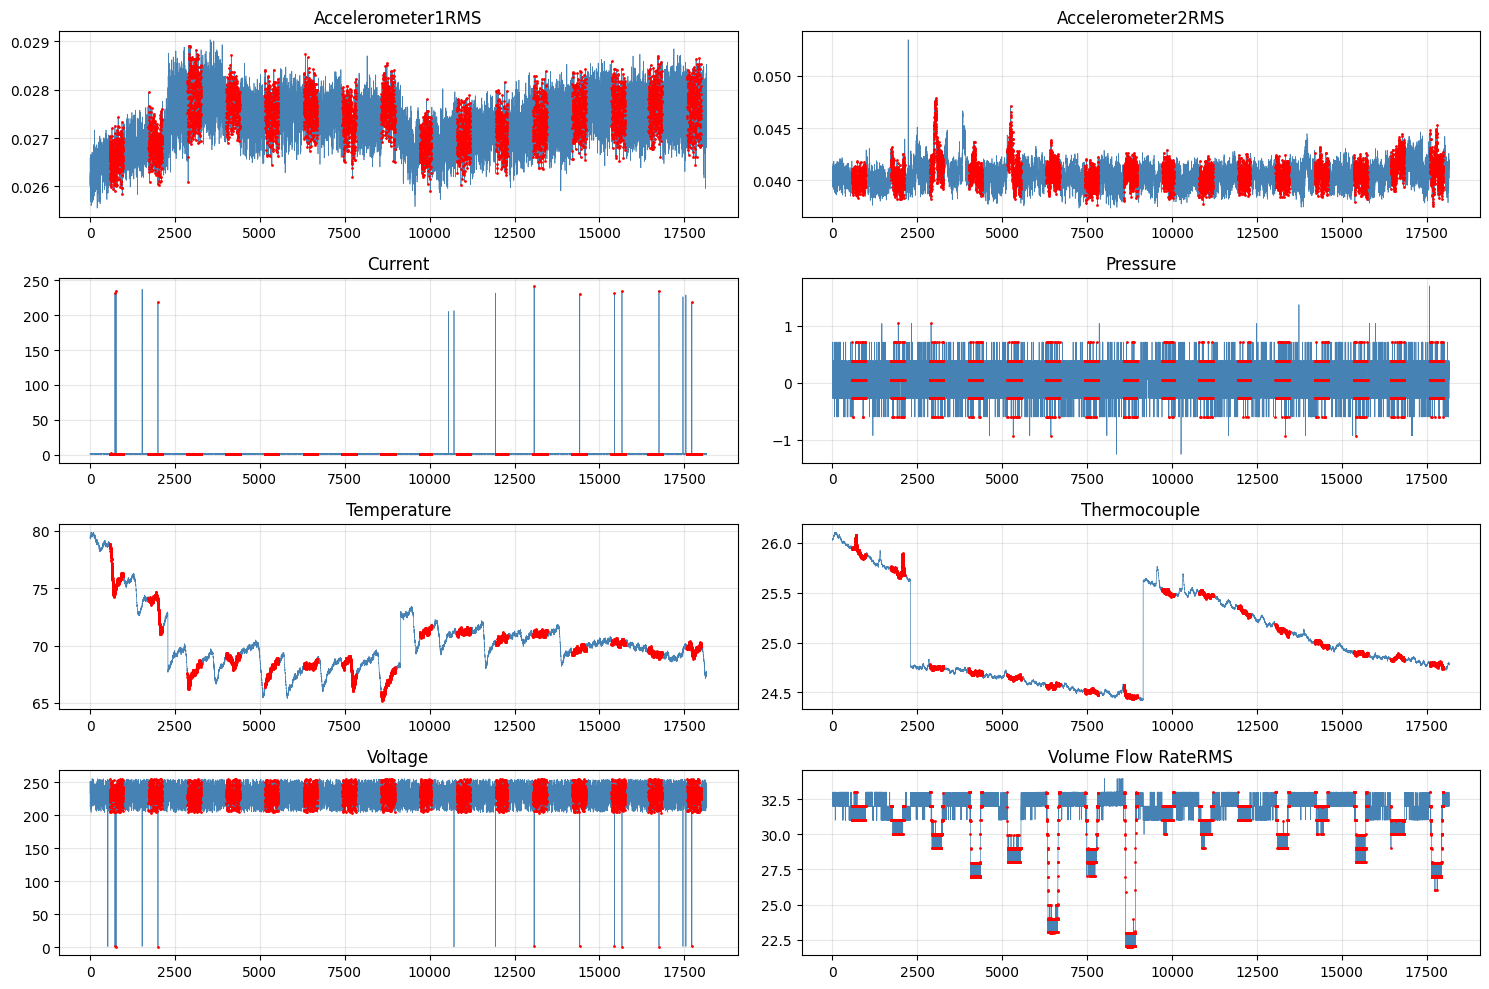

In [3]:
# EDA
fig, axes = plt.subplots(4, 2, figsize=(15, 10))
for i, feat in enumerate(features):
    ax = axes[i//2][i%2]
    ax.plot(test_df[feat].values, linewidth=0.5, color='steelblue')
    anomaly_idx = test_df[test_df['anomaly']==1].index
    ax.scatter(anomaly_idx, test_df[feat].iloc[anomaly_idx],
               color='red', s=1, zorder=5)
    ax.set_title(feat)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# preprocessing
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_data)
test_scaled  = scaler.transform(test_data)

WINDOW_SIZE = 30

def make_windows(data, window_size):
    X = []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size])
    return np.array(X)

X_train = make_windows(train_scaled, WINDOW_SIZE)
X_test  = make_windows(test_scaled, WINDOW_SIZE)
y_test  = test_label[WINDOW_SIZE:]

In [5]:
# model
class TransformerAE(nn.Module):
    def __init__(self, input_dim, d_model=64, nhead=4, num_layers=2):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=128, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=128, batch_first=True
        )
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_layers)
        self.output_proj = nn.Linear(d_model, input_dim)

    def forward(self, x):
        x = self.input_proj(x)
        memory = self.encoder(x)
        out = self.decoder(x, memory)
        return self.output_proj(out)

In [6]:
# training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

X_train_tensor = torch.FloatTensor(X_train).to(device)
X_test_tensor  = torch.FloatTensor(X_test).to(device)

dataset    = TensorDataset(X_train_tensor)
dataloader = DataLoader(dataset, batch_size=256, shuffle=True)

model     = TransformerAE(input_dim=8).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

for epoch in range(50):
    model.train()
    total_loss = 0
    for (batch,) in dataloader:
        optimizer.zero_grad()
        loss = criterion(model(batch), batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    if (epoch+1) % 10 == 0:
        print(f"epoch {epoch+1}/50  loss: {total_loss/len(dataloader):.6f}")

epoch 10/50  loss: 0.001635
epoch 20/50  loss: 0.000631
epoch 30/50  loss: 0.000337
epoch 40/50  loss: 0.000225
epoch 50/50  loss: 0.000165


In [8]:
# baseline: Isolation Forest
from sklearn.ensemble import IsolationForest

X_test_2d = X_test.reshape(len(X_test), -1)
X_train_2d = X_train.reshape(len(X_train), -1)

iso = IsolationForest(contamination=0.35, random_state=42)
iso.fit(X_train_2d)
y_pred_iso = (iso.predict(X_test_2d) == -1).astype(int)

print("Isolation Forest")
print(f"F1        : {f1_score(y_test, y_pred_iso):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_iso):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_iso):.4f}")

Isolation Forest
F1        : 0.5163
Precision : 0.3479
Recall    : 1.0000


F1        : 0.8612
Precision : 0.9300
Recall    : 0.8019


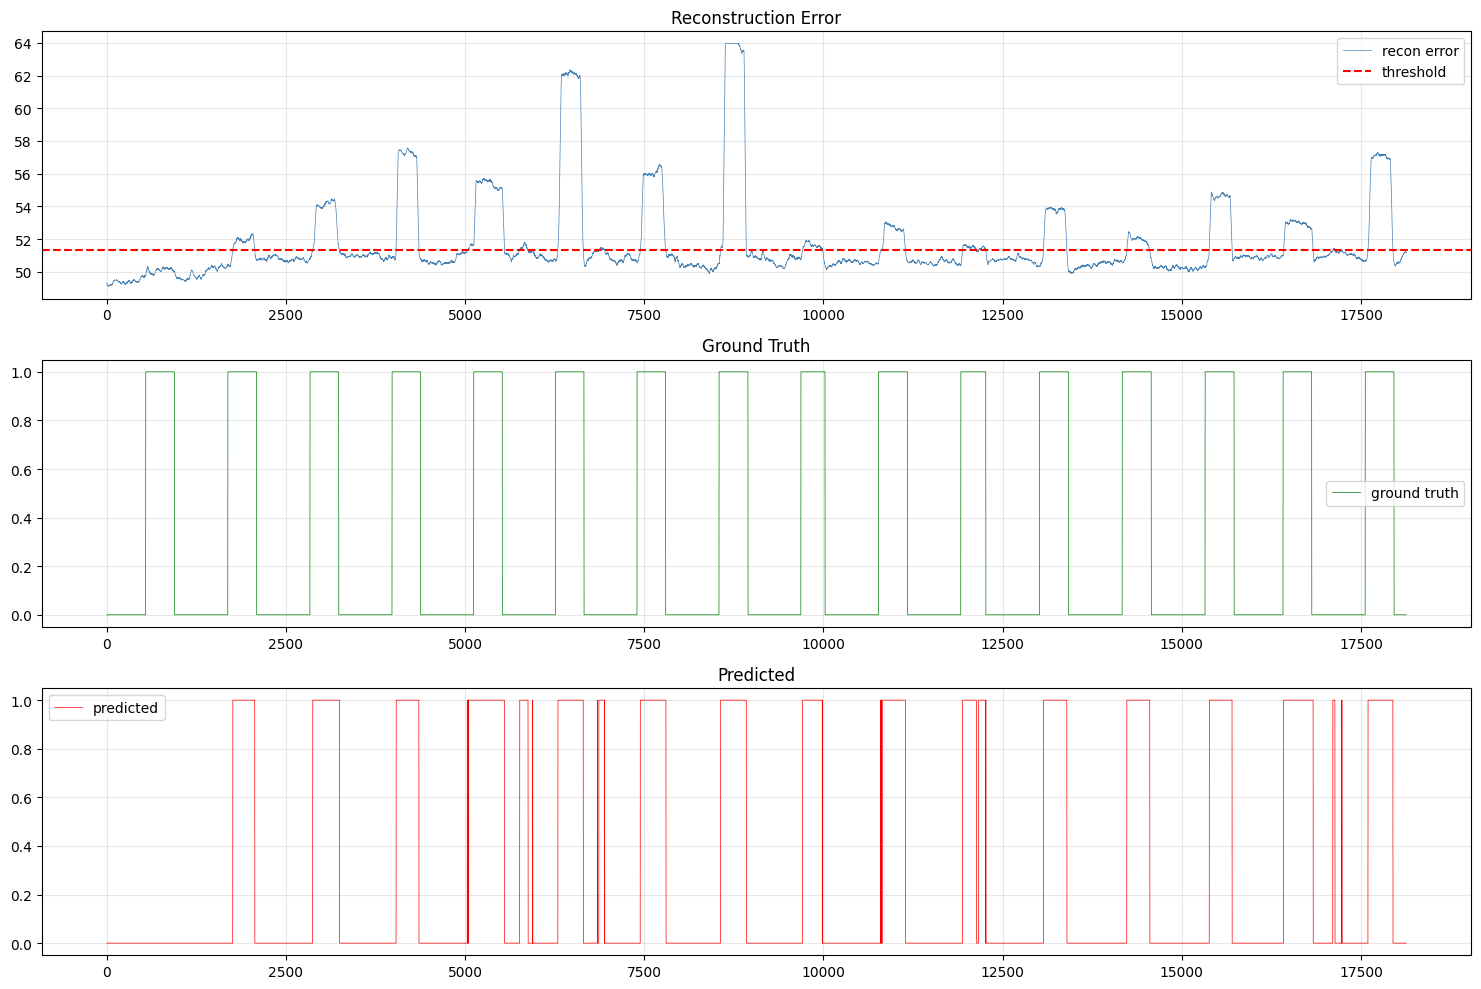

In [7]:
# evaluation
model.eval()
with torch.no_grad():
    recon = model(X_test_tensor).cpu().numpy()

X_test_np = X_test_tensor.cpu().numpy()
recon_error = np.max(np.mean((X_test_np - recon) ** 2, axis=1), axis=1)
recon_clipped = np.clip(recon_error, 0, np.percentile(recon_error, 99))

threshold = np.percentile(recon_clipped, 70)
y_pred = (recon_clipped > threshold).astype(int)

print(f"F1        : {f1_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")

fig, axes = plt.subplots(3, 1, figsize=(15, 10))

axes[0].plot(recon_clipped, linewidth=0.5, color='steelblue', label='recon error')
axes[0].axhline(threshold, color='red', linestyle='--', label='threshold')
axes[0].set_title('Reconstruction Error')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(y_test, linewidth=0.5, color='green', label='ground truth')
axes[1].set_title('Ground Truth')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(y_pred, linewidth=0.5, color='red', label='predicted')
axes[2].set_title('Predicted')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('result.png', dpi=150)
plt.show()